# Stacked Autoencoder

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 0.2233 - val_loss: 0.1309
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - loss: 0.1273 - val_loss: 0.1148
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - loss: 0.1151 - val_loss: 0.1097
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - loss: 0.1100 - val_loss: 0.1067
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 0.1065 - val_loss: 0.1026
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - loss: 0.1045 - val_loss: 0.1014
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 0.1028 - val_loss: 0.0999
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 0.1014 - val_loss: 0.0981
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - loss: 0.0997 - val_loss: 0.0969
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - loss: 0.0983 - val_loss: 0.0959
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step


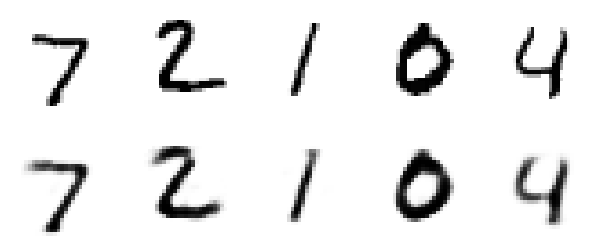

In [ ]:
import keras
from keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D
from keras.models import Model
from keras.datasets import mnist
import numpy as np
import matplotlib.pyplot as plt

(x_train, _), (x_test, _) = mnist.load_data()
x_train = x_train.astype('float32') / 255.
x_test = x_test.astype('float32') / 255.
x_train = np.reshape(x_train, (len(x_train), 28, 28))
x_test = np.reshape(x_test, (len(x_test), 28, 28))

stacked_encoder = keras.models.Sequential([
keras.layers.Flatten(input_shape=[28, 28]),
keras.layers.Dense(100, activation="selu"),
keras.layers.Dense(30, activation="selu"),
])
stacked_decoder = keras.models.Sequential([
keras.layers.Dense(100, activation="selu", input_shape=[30]),
keras.layers.Dense(28 * 28, activation="sigmoid"),
keras.layers.Reshape([28, 28])
])
stacked_ae = keras.models.Sequential([stacked_encoder, stacked_decoder])
stacked_ae.compile(loss="binary_crossentropy",
optimizer=keras.optimizers.SGD(learning_rate=1.5))
history = stacked_ae.fit(x_train, x_train, epochs=10,
validation_data=[x_test, x_test])



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


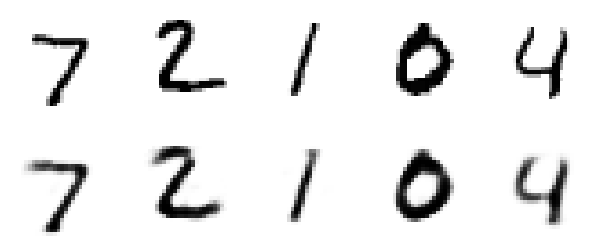

In [ ]:

def plot_image(image):
    plt.imshow(np.squeeze(image), cmap="binary")
    plt.axis("off")
def show_reconstructions(model, n_images=5):
    reconstructions = model.predict(x_test[:n_images])
    fig = plt.figure(figsize=(n_images * 1.5, 3))
    for image_index in range(n_images):
        plt.subplot(2, n_images, 1 + image_index)
        plot_image(x_test[image_index])
        plt.subplot(2, n_images, 1 + n_images + image_index)
        plot_image(reconstructions[image_index])
show_reconstructions(stacked_ae)

# Convolutional Autoencoder

In [ ]:
from keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D
from keras.models import Model
from keras.datasets import mnist
import numpy as np
import matplotlib.pyplot as plt


(x_train, _), (x_test, _) = mnist.load_data()


x_train = x_train.astype('float32') / 255.
x_test = x_test.astype('float32') / 255.
x_train = np.reshape(x_train, (len(x_train), 28, 28, 1))
x_test = np.reshape(x_test, (len(x_test), 28, 28, 1))

# Adding noise
noise_factor = 0.5
x_train_noisy = x_train + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=x_train.shape)
x_test_noisy = x_test + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=x_test.shape)
x_train_noisy = np.clip(x_train_noisy, 0., 1.) # clipped between 0 and 1 to ensure valid pixel intensity range.
x_test_noisy = np.clip(x_test_noisy, 0., 1.) # clipped between 0 and 1 to ensure valid pixel intensity range.

11490434/11490434 [==============================] - 0s 0us/step


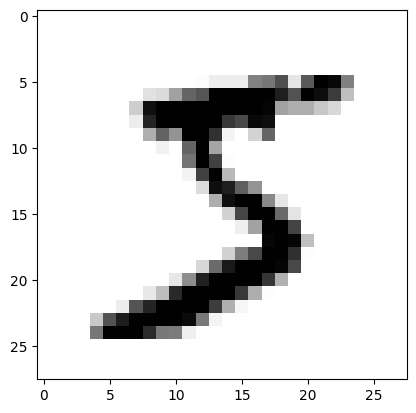

In [ ]:
plt.imshow(x_train[0], cmap='gray_r')

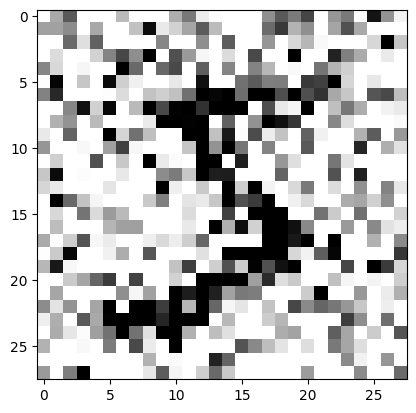

In [ ]:
plt.imshow(x_train_noisy[0], cmap='gray_r')

In [ ]:
input_img = Input(shape=(28, 28, 1))
x = Conv2D(32, (3, 3), activation='relu', padding='same')(input_img)
x = MaxPooling2D((2, 2), padding='same')(x)
x = Conv2D(32, (3, 3), activation='relu', padding='same')(x)
encoded = MaxPooling2D((2, 2), padding='same')(x)

x = Conv2D(32, (3, 3), activation='relu', padding='same')(encoded)
x = UpSampling2D((2, 2))(x)
x = Conv2D(32, (3, 3), activation='relu', padding='same')(x)
x = UpSampling2D((2, 2))(x)
decoded = Conv2D(1, (3, 3), activation='sigmoid', padding='same')(x)

autoencoder = Model(input_img, decoded)
autoencoder.summary()
autoencoder.compile(optimizer='adam', loss='binary_crossentropy')
autoencoder.fit(x_train_noisy, x_train,
                epochs=10,
                batch_size=128,
                shuffle=True,
                validation_data=(x_test_noisy, x_test))

denoised_image = autoencoder.predict(np.array([x_test_noisy[0]]))

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 28, 28, 1)]       0         
                                                                 
 conv2d (Conv2D)             (None, 28, 28, 32)        320       
                                                                 
 max_pooling2d (MaxPooling2  (None, 14, 14, 32)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 14, 14, 32)        9248      
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 7, 7, 32)          0         
 g2D)                                                            
                                                                 
 conv2d_2 (Conv2D)           (None, 7, 7, 32)          9248  

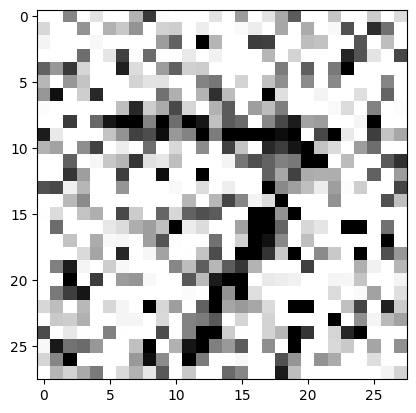

In [ ]:
plt.imshow(x_test_noisy[0], cmap='gray_r')

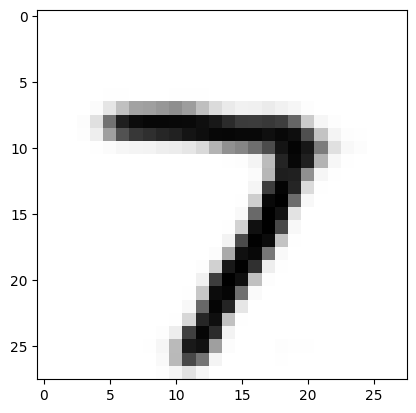

In [ ]:
plt.imshow(denoised_image[0], cmap='gray_r')

Notice how the
autoencoder guesses details that are actually not in the input, such as the shape of the
digit seven and removes so much of the noise.

# Variational Autoencoder

Model: "variational_ae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_images (InputLayer)       │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ variational_encoder             │ [(None, 10), (None,    │       134,870 │
│ (Functional)                    │ 10), (None, 10)]       │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ variational_decoder             │ (None, 28, 28, 1)      │       134,634 │
│ (Functional)                    │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 269,504 (1.03 MB)

 Trainable params: 269,504 (1.03 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - loss: 0.4151 - val_loss: 0.3244
Epoch 2/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - loss: 0.3202 - val_loss: 0.3167
Epoch 3/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - loss: 0.3116 - val_loss: 0.3082
Epoch 4/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - loss: 0.3058 - val_loss: 0.3043
Epoch 5/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - loss: 0.3023 - val_loss: 0.3028
Epoch 6/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - loss: 0.2998 - val_loss: 0.3010
Epoch 7/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - loss: 0.2979 - val_loss: 0.3001
Epoch 8/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - loss: 0.2963 - val_loss: 0.2977
Epoch 9/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - loss: 0.2949 - val_loss: 0.2964
Epoch 10/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - loss: 0.2939 - val_loss: 0.2962
Epoch 11/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - loss: 0.2929 - val_loss: 0.2944
Epoch 12/30
469/469 ━━━━━━━━━━━━━━━━━━━━

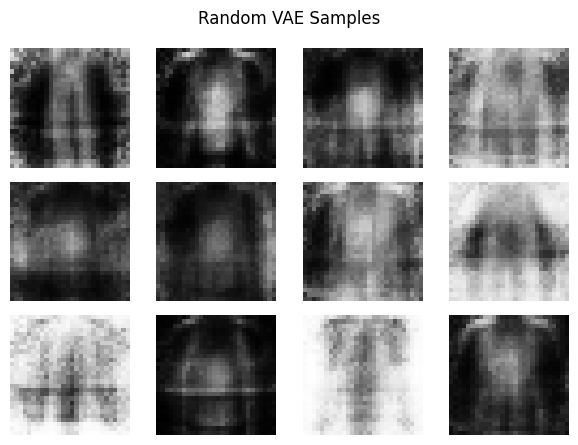

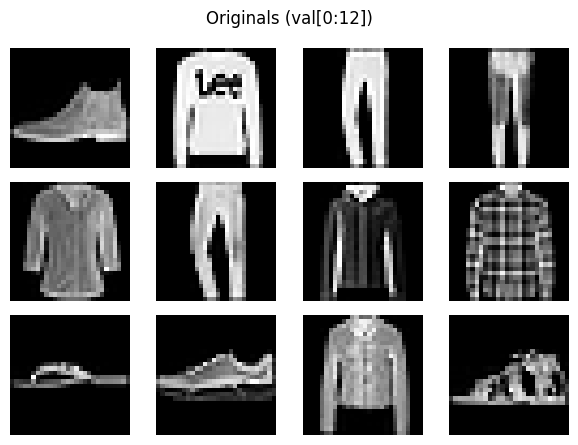

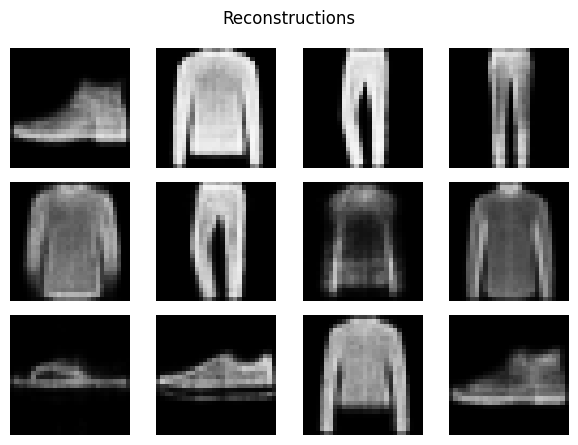

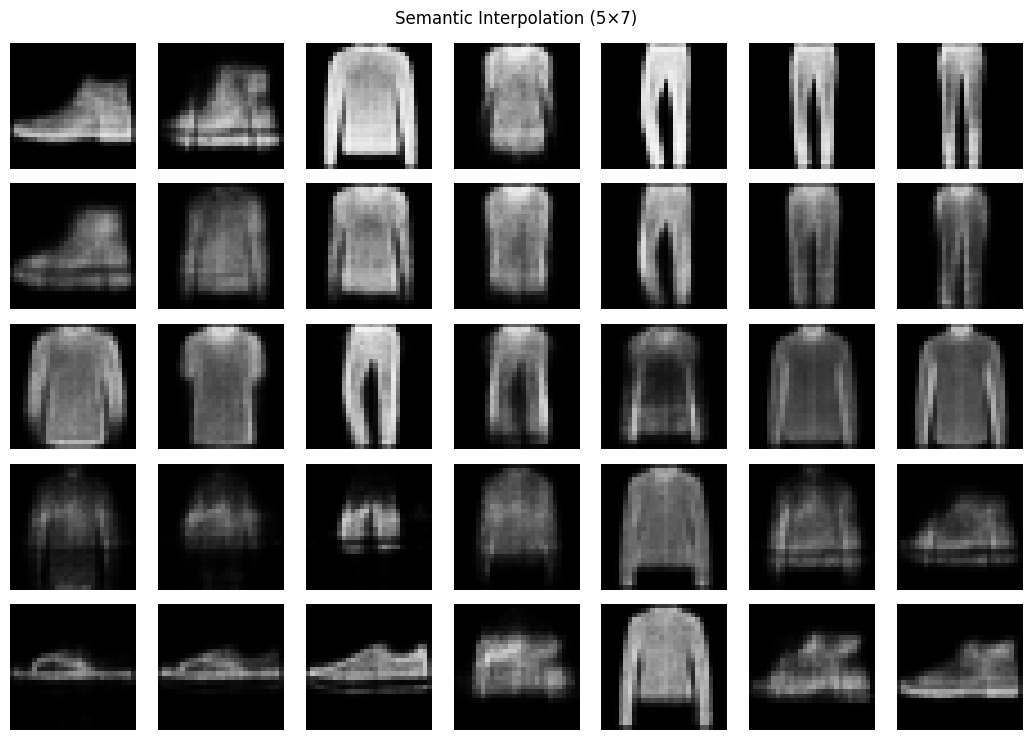

In [ ]:
# ============================================================
# Variational Autoencoder (VAE) on Fashion-MNIST  — Keras 3
#  • Uses gamma = log(var) (numerically stable)
#  • KL term in gamma form via keras.ops (Keras 3 safe)
#  • Includes generation, reconstruction, and interpolation demos
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers, ops

# -----------------------------
# Reproducibility (optional)
# -----------------------------
tf.random.set_seed(42)
np.random.seed(42)

# -----------------------------
# Data: Fashion-MNIST
# -----------------------------
(x_train, _), (x_valid, _) = keras.datasets.fashion_mnist.load_data()

def prep(x: np.ndarray) -> np.ndarray:
    """Normalize to [0,1] and add channel dimension: (N, 28, 28, 1)."""
    x = x.astype("float32") / 255.0
    if x.ndim == 3:
        x = np.expand_dims(x, -1)
    return x

x_train = prep(x_train)
x_valid = prep(x_valid)

# -----------------------------
# Hyperparameters
# -----------------------------
codings_size = 10   # latent dimension
hidden1 = 150
hidden2 = 100
epochs = 30         # increase for better samples
batch_size = 128
lr = 1e-3
beta = 1.0          # β-VAE: set >1 to emphasize KL

# -----------------------------
# Utility: show image grids
# -----------------------------
def show_images_grid(imgs, n_rows, n_cols, title=None, cmap="gray"):
    """Display imgs (N, 28, 28, 1) in an n_rows x n_cols grid."""
    plt.figure(figsize=(1.5*n_cols, 1.5*n_rows))
    for i in range(min(len(imgs), n_rows * n_cols)):
        plt.subplot(n_rows, n_cols, i + 1)
        plt.imshow(imgs[i].squeeze(), cmap=cmap, vmin=0, vmax=1)
        plt.axis("off")
    if title:
        plt.suptitle(title)
    plt.tight_layout()
    plt.show()

# -----------------------------
# Reparameterization: z = μ + exp(0.5*γ) ⊙ ε,  ε ~ N(0,I)
# -----------------------------
class Sampling(layers.Layer):
    """Reparameterization trick sampling layer.

    Inputs:
      [mu, log_var] where log_var = γ = log(σ²)
    Output:
      z sampled from N(mu, σ²)
    """
    def call(self, inputs, **kwargs):
        mu, log_var = inputs
        eps = tf.random.normal(shape=ops.shape(log_var))
        return mu + ops.exp(0.5 * log_var) * eps

# -----------------------------
# KL loss adder (gamma form)
# KL = -1/2 * Σ_i [ 1 + γ_i - μ_i^2 - exp(γ_i) ]
# We scale by 784 to match BCE (mean over pixels) magnitude.
# -----------------------------
class AddKLLoss(layers.Layer):
    """Adds KL loss (batch mean) to the model; passthrough layer."""
    def __init__(self, beta=1.0, **kwargs):
        super().__init__(**kwargs)
        self.beta = beta
    def call(self, inputs, **kwargs):
        mu, log_var = inputs
        kl_per_sample = -0.5 * ops.sum(1.0 + log_var - ops.exp(log_var) - ops.square(mu), axis=-1)
        kl_scaled = (self.beta * kl_per_sample) / 784.0  # balance vs BCE(mean)
        self.add_loss(ops.mean(kl_scaled))
        return inputs  # passthrough

# -----------------------------
# Encoder: (28,28,1) -> (mu, log_var, z)
# -----------------------------
inputs = keras.Input(shape=(28, 28, 1), name="input_images")
h = layers.Flatten(name="flatten")(inputs)
h = layers.Dense(hidden1, activation="selu", name="enc_dense1")(h)
h = layers.Dense(hidden2, activation="selu", name="enc_dense2")(h)
mu = layers.Dense(codings_size, name="z_mean")(h)            # μ
log_var = layers.Dense(codings_size, name="z_log_var")(h)    # γ = log(σ²)

# Add KL loss to the model (before sampling)
_ = AddKLLoss(beta=beta, name="kl_loss")([mu, log_var])

z = Sampling(name="z")([mu, log_var])
variational_encoder = keras.Model(inputs=inputs, outputs=[mu, log_var, z], name="variational_encoder")

# -----------------------------
# Decoder: z -> image (28,28,1)
# -----------------------------
z_in = keras.Input(shape=(codings_size,), name="z_input")
d = layers.Dense(hidden2, activation="selu", name="dec_dense1")(z_in)
d = layers.Dense(hidden1, activation="selu", name="dec_dense2")(d)
d = layers.Dense(28 * 28, activation="sigmoid", name="dec_out")(d)
outputs = layers.Reshape((28, 28, 1), name="reshape_out")(d)
variational_decoder = keras.Model(inputs=z_in, outputs=outputs, name="variational_decoder")

# -----------------------------
# VAE: input -> encoder -> decoder
# -----------------------------
_, _, z_out = variational_encoder(inputs)
recons = variational_decoder(z_out)
variational_ae = keras.Model(inputs=inputs, outputs=recons, name="variational_ae")

# Compile:
#  • Recon loss = BCE (Keras returns mean over pixels)
#  • KL added via AddKLLoss (already scaled)
variational_ae.compile(optimizer=keras.optimizers.RMSprop(learning_rate=lr),
                       loss="binary_crossentropy")

variational_ae.summary()

# -----------------------------
# Train
# -----------------------------
history = variational_ae.fit(
    x_train, x_train,
    validation_data=(x_valid, x_valid),
    epochs=epochs,
    batch_size=batch_size,
    shuffle=True,
    verbose=1
)

# -----------------------------
# Random generation
# -----------------------------
n_gen = 12
z_samples = tf.random.normal(shape=(n_gen, codings_size))
gen_images = variational_decoder(z_samples).numpy()
show_images_grid(gen_images, n_rows=3, n_cols=4, title="Random VAE Samples")

# -----------------------------
# Reconstructions (sanity check)
# -----------------------------
seed_imgs = x_valid[:12]
recons_check = variational_ae.predict(seed_imgs, verbose=0)
show_images_grid(seed_imgs, n_rows=3, n_cols=4, title="Originals (val[0:12])")
show_images_grid(recons_check, n_rows=3, n_cols=4, title="Reconstructions")

# -----------------------------
# Semantic interpolation (latent space)
# 1) Encode 12 validation images to z
# 2) Arrange into 3x4 grid
# 3) Resize to 5x7 with bilinear interpolation (adds in-between codes)
# 4) Decode all to visualize smooth transitions
# -----------------------------
encoder_z = keras.Model(inputs=variational_encoder.input, outputs=variational_encoder.outputs[2])
seed_codes = encoder_z.predict(seed_imgs, verbose=0)               # (12, K)
grid_3x4 = tf.reshape(seed_codes, [1, 3, 4, codings_size])         # (1,3,4,K)
grid_5x7 = tf.image.resize(grid_3x4, size=[5, 7], method="bilinear")
interp_codes = tf.reshape(grid_5x7, [-1, codings_size])            # (35, K)
interp_images = variational_decoder(interp_codes).numpy()          # (35, 28, 28, 1)
show_images_grid(interp_images, n_rows=5, n_cols=7, title="Semantic Interpolation (5×7)")


# Generative Adversarial Networks

In [1]:
import sys
assert sys.version_info >= (3, 7)
from packaging import version
import sklearn
assert version.parse(sklearn.__version__) >= version.parse("1.0.1")

import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"
import tf_keras
import tensorflow as tf
assert version.parse(tf.__version__) >= version.parse("2.8.0")
import numpy as np
import matplotlib.pyplot as plt


In [2]:
fashion_mnist = tf.keras.datasets.fashion_mnist.load_data()
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist
X_train_full = X_train_full.astype(np.float32) / 255
X_test = X_test.astype(np.float32) / 255
X_train, X_valid = X_train_full[:-5000], X_train_full[-5000:]
y_train, y_valid = y_train_full[:-5000], y_train_full[-5000:]

In [3]:
def plot_multiple_images(images, n_cols=None):
    n_cols = n_cols or len(images)
    n_rows = (len(images) - 1) // n_cols + 1
    if images.shape[-1] == 1:
        images = images.squeeze(axis=-1)
    plt.figure(figsize=(n_cols, n_rows))
    for index, image in enumerate(images):
        plt.subplot(n_rows, n_cols, index + 1)
        plt.imshow(image, cmap="binary")
        plt.axis("off")


In [4]:
tf.random.set_seed(42)

codings_size = 30

Dense = tf.keras.layers.Dense
generator = tf.keras.Sequential([
    Dense(100, activation="relu", kernel_initializer="he_normal"),
    Dense(150, activation="relu", kernel_initializer="he_normal"),
    Dense(28 * 28, activation="sigmoid"),
    tf.keras.layers.Reshape([28, 28])
])
discriminator = tf.keras.Sequential([
    tf.keras.layers.Flatten(),
    Dense(150, activation="relu", kernel_initializer="he_normal"),
    Dense(100, activation="relu", kernel_initializer="he_normal"),
    Dense(1, activation="sigmoid")
])
gan = tf.keras.Sequential([generator, discriminator])

In [5]:
discriminator.compile(loss="binary_crossentropy", optimizer="rmsprop")
discriminator.trainable = False
gan.compile(loss="binary_crossentropy", optimizer="rmsprop")

In [6]:
batch_size = 32
dataset = tf.data.Dataset.from_tensor_slices(X_train).shuffle(1000)
dataset = dataset.batch(batch_size, drop_remainder=True).prefetch(1)

Epoch 1/20


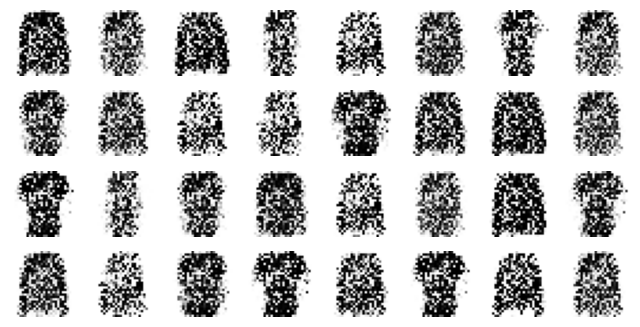

Epoch 2/20


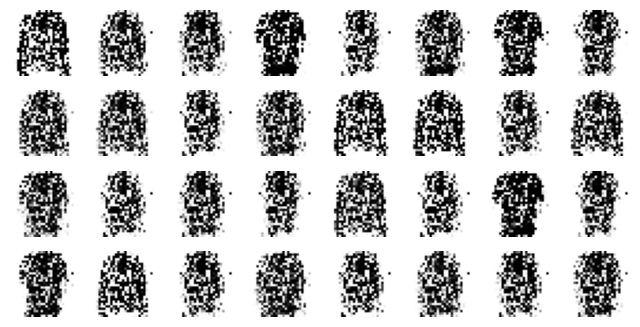

Epoch 3/20


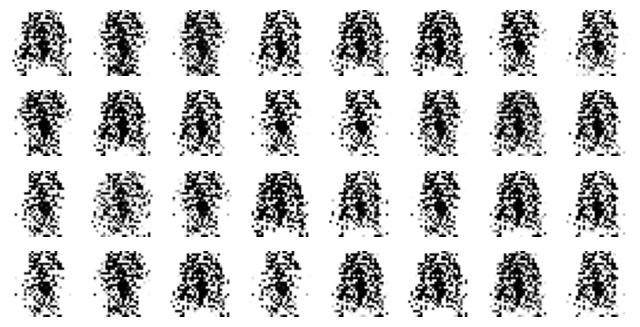

Epoch 4/20


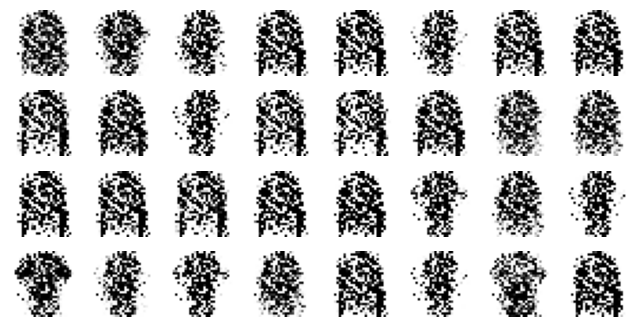

Epoch 5/20


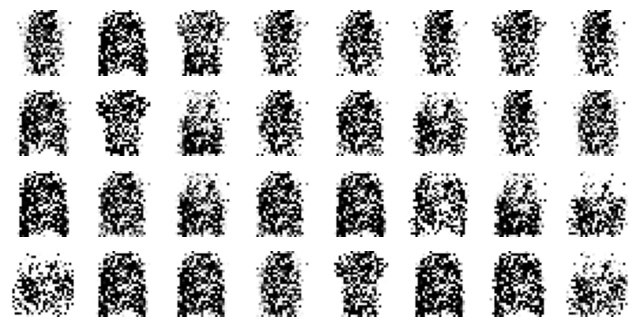

Epoch 6/20


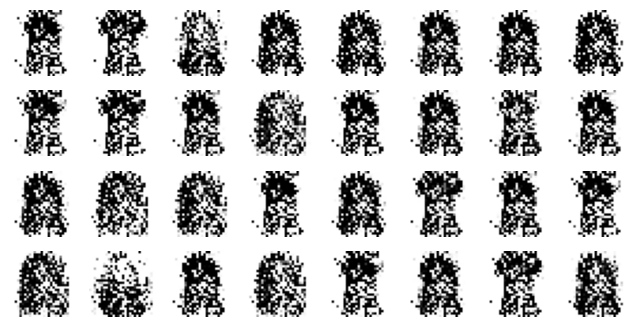

Epoch 7/20


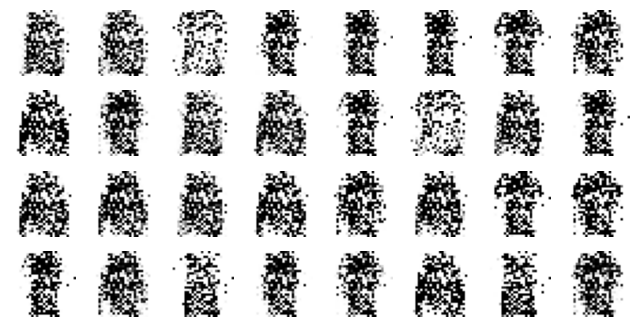

Epoch 8/20


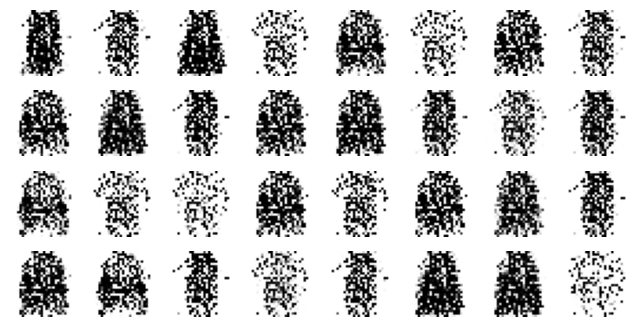

Epoch 9/20


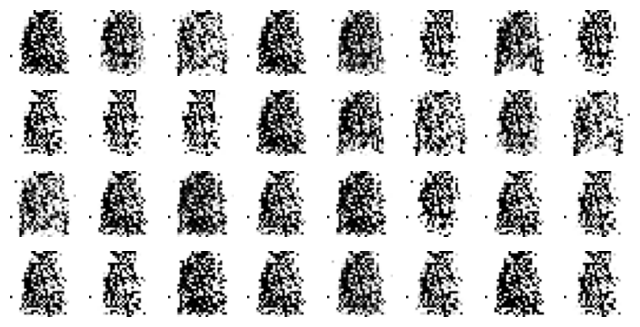

Epoch 10/20


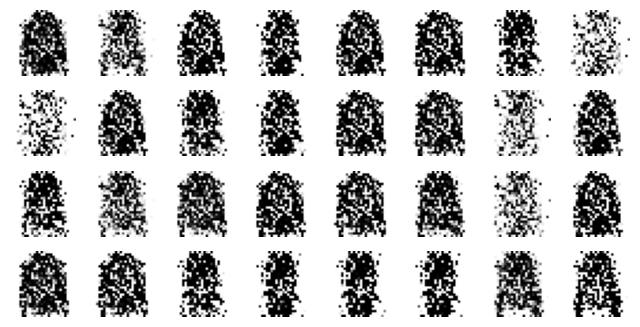

Epoch 11/20


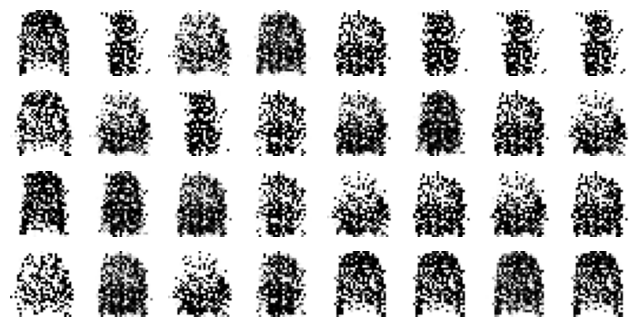

Epoch 12/20


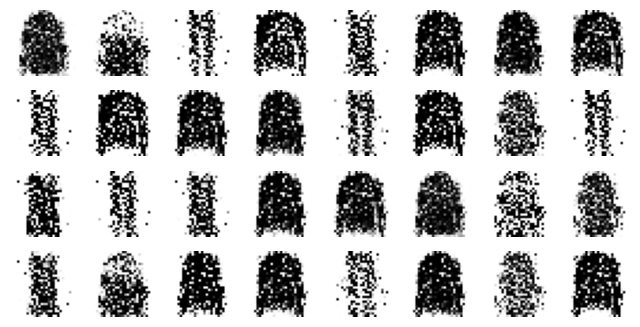

Epoch 13/20


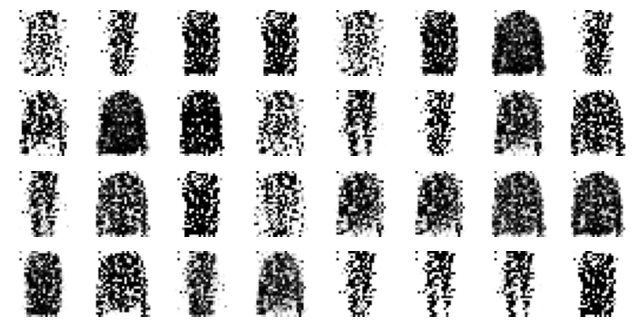

Epoch 14/20


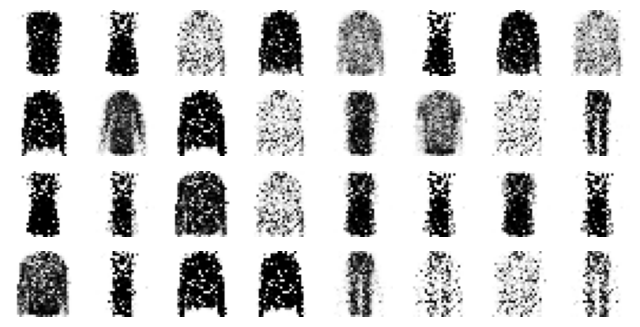

Epoch 15/20


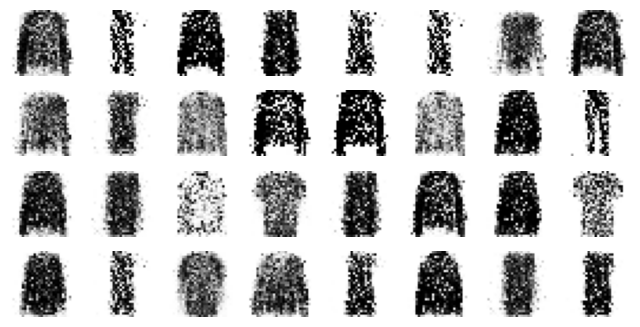

Epoch 16/20


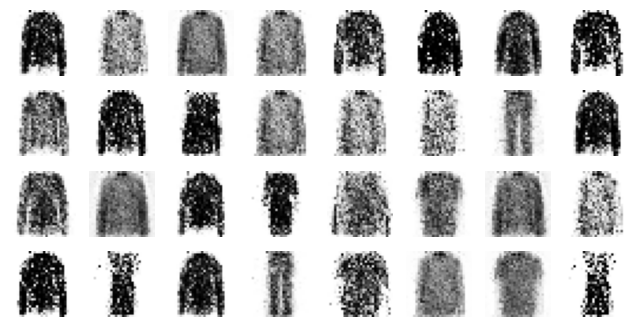

Epoch 17/20


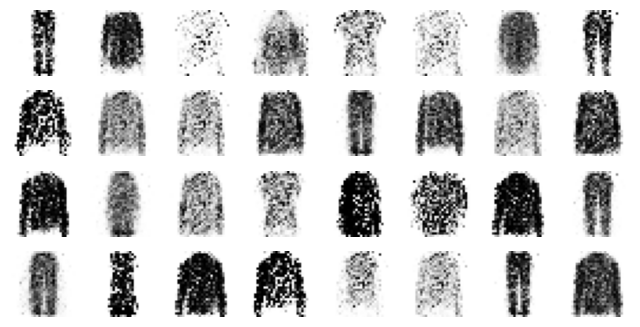

Epoch 18/20


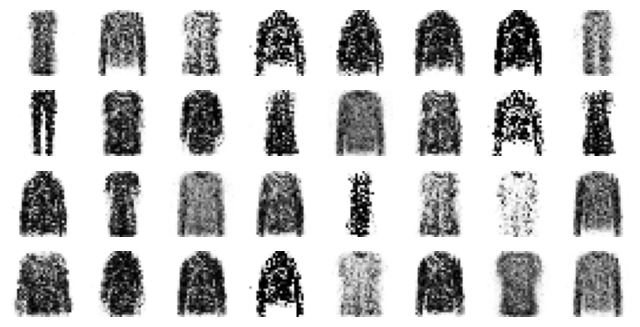

Epoch 19/20


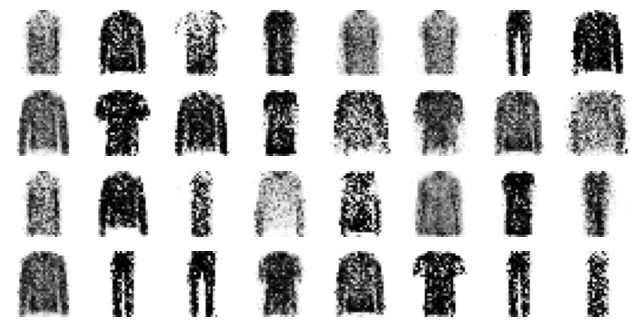

Epoch 20/20


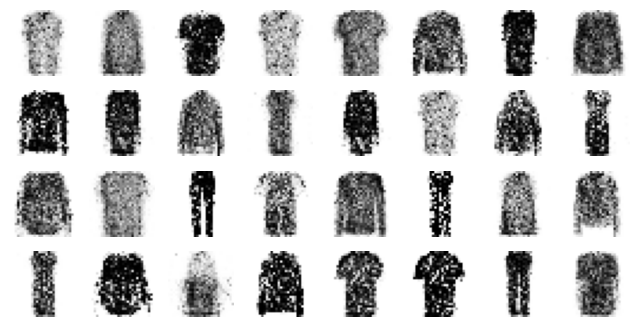

In [7]:
def train_gan(gan, dataset, batch_size, codings_size, n_epochs):
    generator, discriminator = gan.layers
    for epoch in range(n_epochs):
        print(f"Epoch {epoch + 1}/{n_epochs}")  # extra code
        for X_batch in dataset:
            # phase 1 - training the discriminator
            noise = tf.random.normal(shape=[batch_size, codings_size])
            generated_images = generator(noise)
            X_fake_and_real = tf.concat([generated_images, X_batch], axis=0)
            y1 = tf.constant([[0.]] * batch_size + [[1.]] * batch_size)
            discriminator.train_on_batch(X_fake_and_real, y1)
            # phase 2 - training the generator
            noise = tf.random.normal(shape=[batch_size, codings_size])
            y2 = tf.constant([[1.]] * batch_size)
            gan.train_on_batch(noise, y2)
        # extra code — plot images during training
        plot_multiple_images(generated_images.numpy(), 8)
        plt.show()

train_gan(gan, dataset, batch_size, codings_size, n_epochs=20)

In [8]:
tf.random.set_seed(42)
codings = tf.random.normal(shape=[batch_size, codings_size])
generated_images = generator.predict(codings)

1/1 [==============================] - 0s 91ms/step


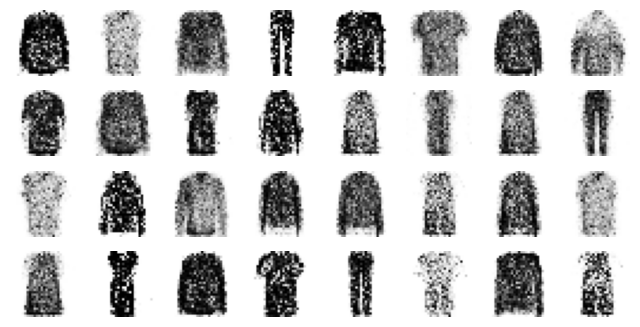

In [9]:
plot_multiple_images(generated_images, 8)

plt.show()

# Deep Convolutional GAN

In [10]:
tf.random.set_seed(42)

generator = tf.keras.Sequential([
    tf.keras.layers.Dense(7 * 7 * 128),
    tf.keras.layers.Reshape([7, 7, 128]),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2DTranspose(64, kernel_size=5, strides=2,
                                    padding="same", activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2DTranspose(1, kernel_size=5, strides=2,
                                    padding="same", activation="tanh"),
])
discriminator = tf.keras.Sequential([
    tf.keras.layers.Conv2D(64, kernel_size=5, strides=2, padding="same",
                        activation=tf.keras.layers.LeakyReLU(0.2)),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Conv2D(128, kernel_size=5, strides=2, padding="same",
                        activation=tf.keras.layers.LeakyReLU(0.2)),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(1, activation="sigmoid")
])
gan = tf.keras.Sequential([generator, discriminator])

In [11]:
# compiles the discrimator and the gan, as earlier
discriminator.compile(loss="binary_crossentropy", optimizer="rmsprop")
discriminator.trainable = False
gan.compile(loss="binary_crossentropy", optimizer="rmsprop")

In [13]:
X_train_dcgan = X_train.reshape(-1, 28, 28, 1) * 2. - 1. # reshape and rescale

Epoch 1/20


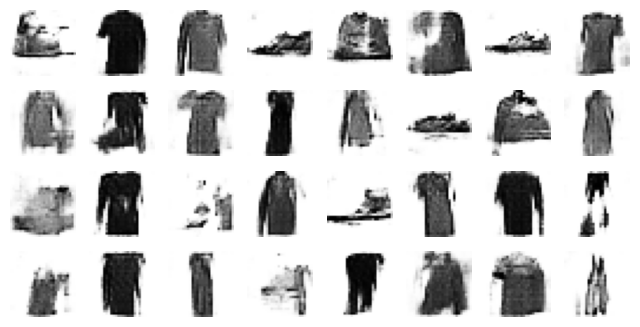

Epoch 2/20


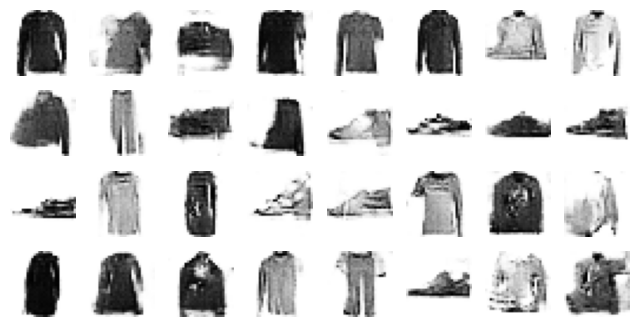

Epoch 3/20


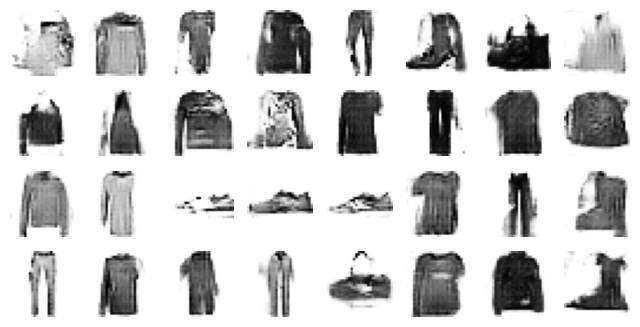

Epoch 4/20


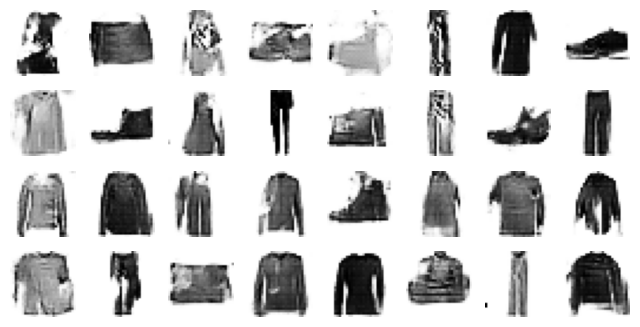

Epoch 5/20


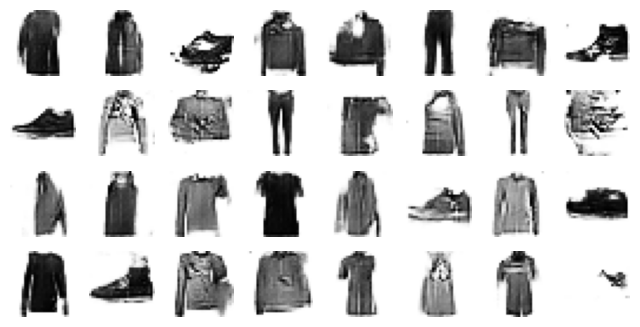

Epoch 6/20


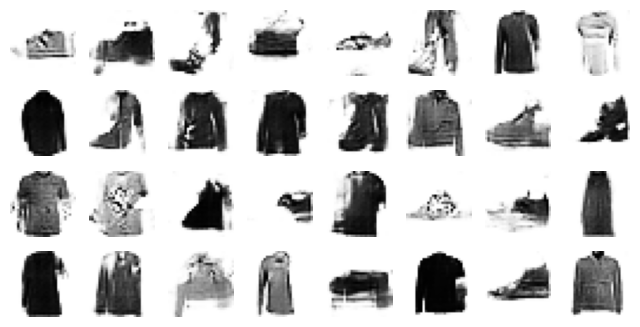

Epoch 7/20


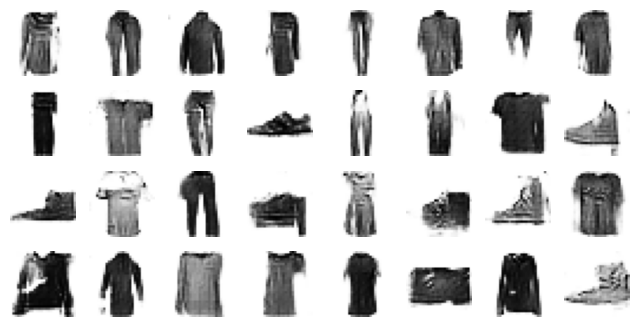

Epoch 8/20


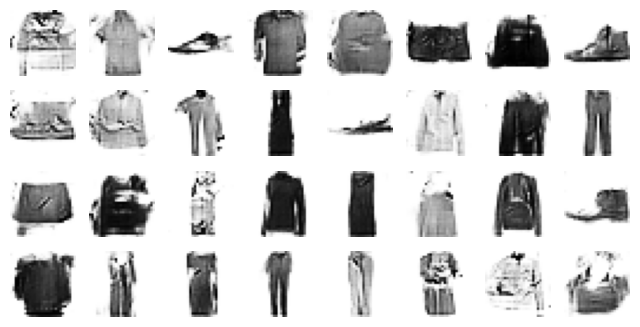

Epoch 9/20


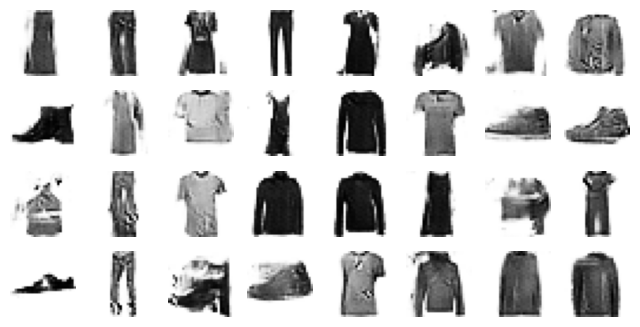

Epoch 10/20


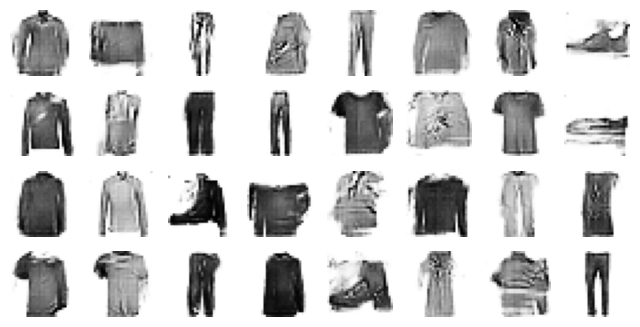

Epoch 11/20


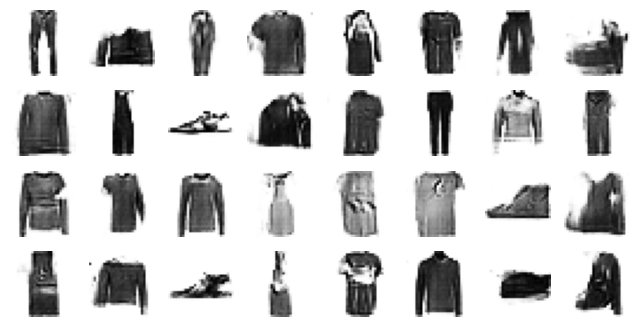

Epoch 12/20


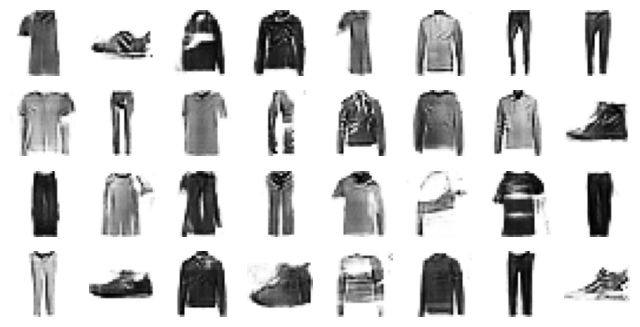

Epoch 13/20


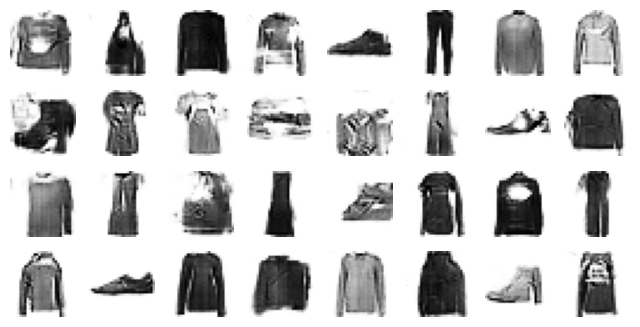

Epoch 14/20


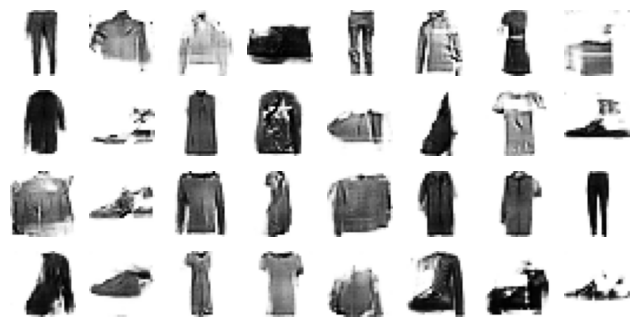

Epoch 15/20


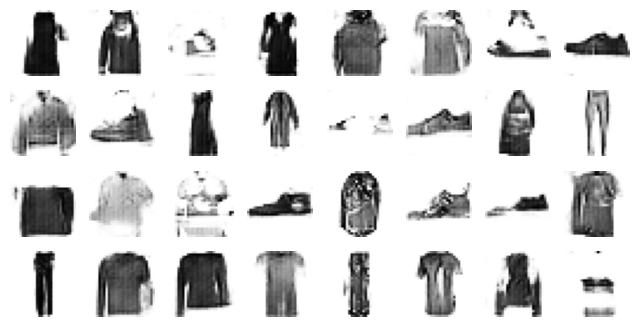

Epoch 16/20


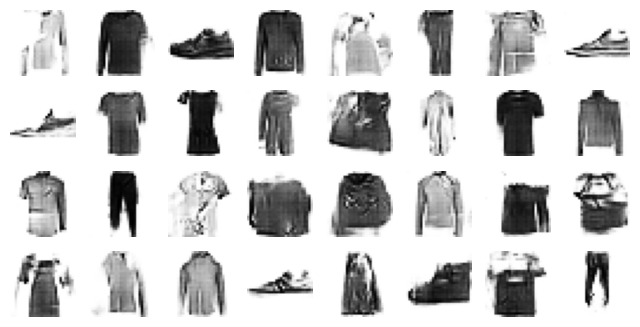

Epoch 17/20


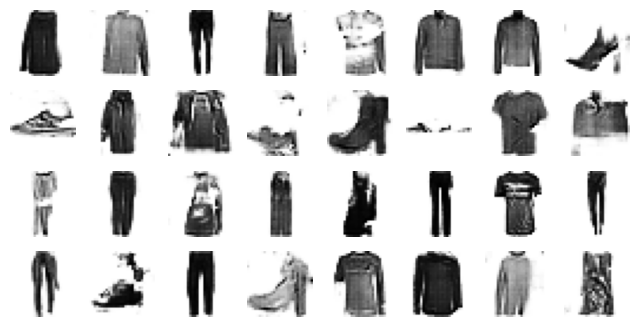

Epoch 18/20


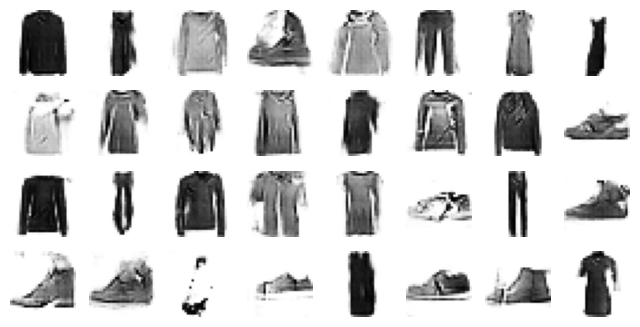

Epoch 19/20


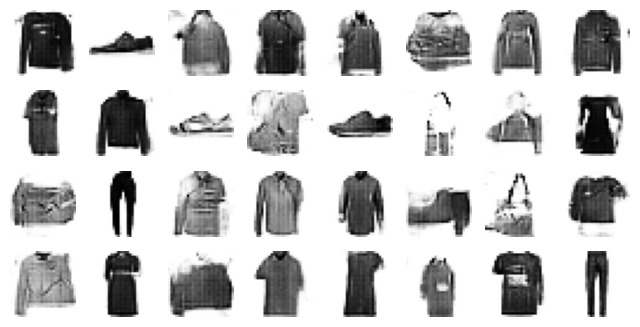

Epoch 20/20


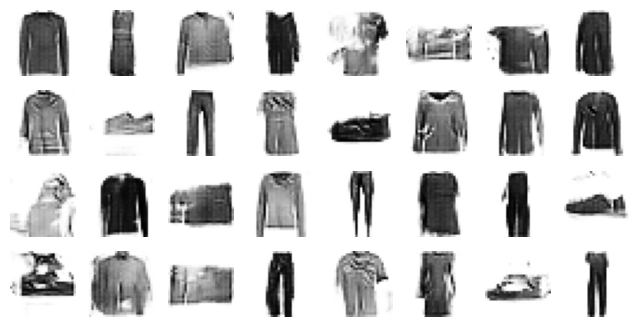

In [15]:
# generates the dataset and trains the GAN, just like earlier
batch_size = 32
dataset = tf.data.Dataset.from_tensor_slices(X_train_dcgan)
dataset = dataset.shuffle(1000)
dataset = dataset.batch(batch_size, drop_remainder=True).prefetch(1)
train_gan(gan, dataset, batch_size, codings_size, n_epochs=20)

1/1 [==============================] - 0s 107ms/step


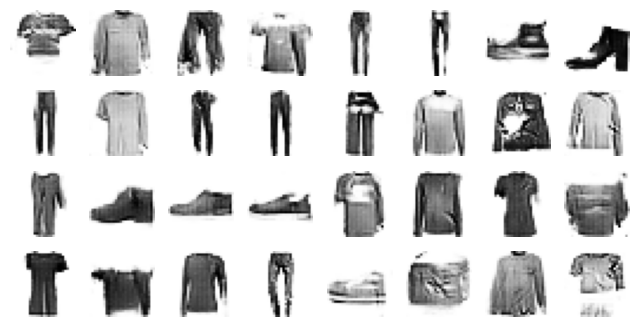

In [16]:
tf.random.set_seed(42)
noise = tf.random.normal(shape=[batch_size, codings_size])
generated_images = generator.predict(noise)
plot_multiple_images(generated_images, 8)